# Reversible Planar CV (`NernstianEquilibrium`)

## 1. Goal

Simulate a diffusion-controlled reversible one-electron transfer (`NernstianEquilibrium`) at a planar electrode and verify its classic diagnostic signatures: $\Delta E_p \approx 57\text{ mV}$, $E_{1/2} = E^{0\prime}$, $|I_{pa}/I_{pc}| = 1$, and $I_{pc} = I_{\text{Randles-Ševčík}}$.

## 2. Physical Setup

We set $E^{0\prime} = 0.0\text{ V}$, $D_{\text{Ox}} = D_{\text{Red}} = 10^{-9}\text{ m}^2/\text{s}$, $c^* = 1\text{ mM}$, $v = 0.1\text{ V/s}$, and scan from $+0.4\text{ V}$ to $-0.4\text{ V}$ and back.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt

from softpotato import analytical as spa
from softpotato.geometry import PlanarGeometry
from softpotato.reactions import NernstianEquilibrium, Species
from softpotato.techniques import (
    CyclicVoltammetry,
    find_peaks,
    plot_concentration_profile,
    plot_peaks,
    simulate,
)

E0 = 0.0
D = 1.0e-9
c_bulk = 1.0
area = 7.07e-6
v = 0.1

ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, standard_potential=E0, n_electrons=1)
red = Species("Red", diffusivity=D, bulk_concentration=0.0)
nernst = NernstianEquilibrium(E0=E0, n=1)
geometry = PlanarGeometry(area)

## 3. Simulation

We run `simulate()` with `NernstianEquilibrium` boundary conditions.

In [2]:
cv = CyclicVoltammetry(E_start=0.4, E_vertex1=-0.4, E_vertex2=0.4, scan_rate=v, dE=0.002)
result = simulate(cv, [ox, red], geometry=geometry, kinetics=nernst)

## 4. Diagnostics & Plots

We inspect the peak diagnostics via `find_peaks()`, compare $I_{pc}$ against `spa.randles_sevcik()`, and plot the spatial concentration profiles at the switching potential.

E_pc = -0.0285 V | E_pa = 0.0290 V
delta_Ep = 57.50 mV (theory ~57–59 mV)
E_half   = 0.0003 V (E0 = 0.0000 V)
|I_pa/I_pc| = 0.777
I_pc (sim) = -19.00 uA | Randles-Sevcik = -18.99 uA


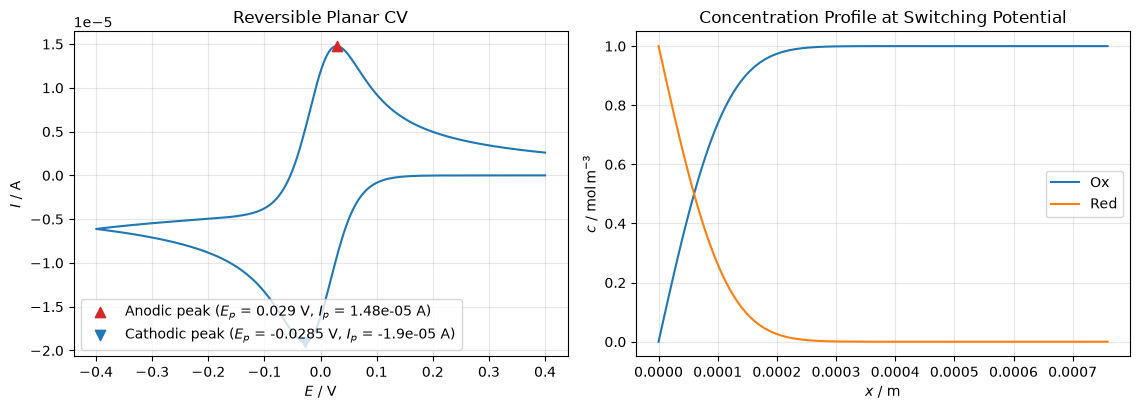

In [3]:
peaks = find_peaks(result)
ip_rs = spa.randles_sevcik(v, c_bulk=c_bulk, D=D, area=area, n=1)

print(f"E_pc = {peaks.cathodic_peak.E_peak:.4f} V | E_pa = {peaks.anodic_peak.E_peak:.4f} V")
print(f"delta_Ep = {peaks.delta_Ep * 1e3:.2f} mV (theory ~57–59 mV)")
print(f"E_half   = {peaks.E_half:.4f} V (E0 = {E0:.4f} V)")
print(f"|I_pa/I_pc| = {peaks.peak_current_ratio:.3f}")
print(f"I_pc (sim) = {peaks.cathodic_peak.I_peak * 1e6:.2f} uA | Randles-Sevcik = {ip_rs * 1e6:.2f} uA")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
plot_peaks(result, ax=axes[0])
axes[0].set_title("Reversible Planar CV")

plot_concentration_profile(result, t=cv.event_times[0], ax=axes[1])
axes[1].set_title("Concentration Profile at Switching Potential")

plt.tight_layout()
plt.show()

## 5. Key Takeaways

- At 298.15 K, a reversible planar 1-$e^-$ couple exhibits $\Delta E_p \approx 57\text{–}59\text{ mV}$, $E_{1/2} = E^{0\prime}$ (when $D_{\text{Ox}} = D_{\text{Red}}$), and $|I_{pa}/I_{pc}| = 1$.
- The diffusion layer grows to $\sim 6\sqrt{D t}$ into solution, depleting $\text{Ox}$ near $x = 0$ and generating $\text{Red}$.
- **Next**: See how curvature changes the voltammogram in [Reversible Spherical CV](cv_nernst_spherical.ipynb).